# Step 5 - PatchCore on  tealight dataset



In [1]:
!git clone -q https://github.com/amazon-science/patchcore-inspection.git
%cd /content/patchcore-inspection
!git rev-parse HEAD
!pip install -q faiss-cpu pretrainedmodels click scikit-image

p = "bin/run_patchcore.py"
s = open(p).read()
s = s.replace('dataloaders["testing"].dataset.transform_std', '[0.229, 0.224, 0.225]')
s = s.replace('dataloaders["testing"].dataset.transform_mean', '[0.485, 0.456, 0.406]')
hook = '''            import pandas as _pd
            _pd.DataFrame({"image": [x[2] for x in dataloaders["testing"].dataset.data_to_iterate],
                           "is_anomaly": anomaly_labels, "score": scores}).to_csv(
                os.path.join(run_save_path, "scores_" + dataset_name + ".csv"), index=False)
            np.save(os.path.join(run_save_path, "segmentations_" + dataset_name + ".npy"), segmentations)

            # (Optional) Plot example images.'''
assert "# (Optional) Plot example images." in s
s = s.replace("            # (Optional) Plot example images.", hook, 1)
open(p, "w").write(s)
!git diff --stat

/content/patchcore-inspection
fcaa92f124fb1ad74a7acf56726decd4b27cbcad
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
 bin/run_patchcore.py | 10 ++++++++--
 1 file changed, 8 insertions(+), 2 deletions(-)


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, glob, shutil, subprocess, datetime, torch, torchvision, faiss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

BASE = "/content/drive/MyDrive/COMP8240_PatchCore"
SRC = f"{BASE}/tealights_mvtec/tealight"
OUT_DIR = f"{BASE}/step5_tealights"
os.makedirs(f"{OUT_DIR}/raw_results", exist_ok=True)

env = {
    "date": datetime.datetime.now().isoformat(timespec="minutes"),
    "python": sys.version.split()[0], "torch": torch.__version__,
    "torchvision": torchvision.__version__, "faiss": faiss.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "repo_commit": subprocess.check_output(["git", "rev-parse", "HEAD"]).decode().strip(),
}
print(json.dumps(env, indent=2))
json.dump(env, open(f"{OUT_DIR}/environment.json", "w"), indent=2)

Mounted at /content/drive
{
  "date": "2026-11-04T04:39",
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "faiss": "1.15.1",
  "gpu": "Tesla T4",
  "repo_commit": "fcaa92f124fb1ad74a7acf56726decd4b27cbcad"
}


## Copy the dataset to the local disk

In [3]:
DATA = "/content/datasets/tealights"
shutil.rmtree(DATA, ignore_errors=True)
shutil.copytree(SRC, f"{DATA}/tealight")

# same training and good test images, but only one defect type in each
for d in ["used", "empty"]:
    for sub in ["train/good", "test/good", f"test/{d}", f"ground_truth/{d}"]:
        shutil.copytree(f"{DATA}/tealight/{sub}", f"{DATA}/tealight_{d}/{sub}")

for c in sorted(os.listdir(DATA)):
    counts = {f"test/{t}": len(os.listdir(f"{DATA}/{c}/test/{t}")) for t in sorted(os.listdir(f"{DATA}/{c}/test"))}
    print(c, "train:", len(os.listdir(f"{DATA}/{c}/train/good")), counts)
# every defect image needs a mask with the same name + _mask
for d in ["used", "empty"]:
    imgs = {f[:-4] for f in os.listdir(f"{DATA}/tealight/test/{d}")}
    msks = {f[:-9] for f in os.listdir(f"{DATA}/tealight/ground_truth/{d}")}
    print(d, "images without a mask:", sorted(imgs - msks))

tealight train: 41 {'test/empty': 46, 'test/good': 18, 'test/used': 49}
tealight_empty train: 41 {'test/empty': 46, 'test/good': 18}
tealight_used train: 41 {'test/good': 18, 'test/used': 49}
used images without a mask: []
empty images without a mask: []


## Run PatchCore

In [4]:
%%bash
cd /content/patchcore-inspection
time PYTHONPATH=src python bin/run_patchcore.py --gpu 0 --seed 0 --save_segmentation_images \
  --log_group WR50_tealight --log_project official results \
  patch_core -b wideresnet50 -le layer2 -le layer3 \
  --pretrain_embed_dimension 1024 --target_embed_dimension 1024 \
  --anomaly_scorer_num_nn 1 --patchsize 3 \
  sampler -p 0.1 approx_greedy_coreset \
  dataset --resize 256 --imagesize 224 -d tealight -d tealight_used -d tealight_empty mvtec /content/datasets/tealights
# save to Drive straight away
cp -r results/official/WR50_tealight* /content/drive/MyDrive/COMP8240_PatchCore/step5_tealights/raw_results/
ls /content/drive/MyDrive/COMP8240_PatchCore/step5_tealights/raw_results/

Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth
WR50_tealight


INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --save_segmentation_images --log_group WR50_tealight --log_project official results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d tealight -d tealight_used -d tealight_empty mvtec /content/datasets/tealights
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__main__:Evaluating dataset [mvtec_tealight] (1/3)

## Results table


In [5]:
RUN = sorted(glob.glob(f"{OUT_DIR}/raw_results/WR50_tealight*"))[-1]
raw = pd.read_csv(f"{RUN}/results.csv")
res = raw[raw[raw.columns[0]] != "Mean"].set_index(raw.columns[0])
res.index = res.index.str.replace("mvtec_", "", regex=False)
res = (res * 100).round(1)
display(res)
res.to_csv(f"{OUT_DIR}/tealight_results.csv")

,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
Row Names,,,
tealight,100.0,97.0,96.2
tealight_used,100.0,92.3,89.0
tealight_empty,100.0,99.6,99.2


## Per-image scores and PatchCore's decision


In [6]:
from sklearn.metrics import precision_recall_curve

sc = pd.read_csv(glob.glob(f"{RUN}/scores_mvtec_tealight.csv")[0])
sc["type"] = sc.image.str.split("/").str[-2]
sc["name"] = sc.image.str.split("/").str[-1].str.replace(".png", "", regex=False)

p, r, t = precision_recall_curve(sc.is_anomaly, sc.score)
f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
thr = t[np.argmax(f1[:-1])]
sc["patchcore_defective"] = sc.score >= thr
sc["correct"] = sc.patchcore_defective == sc.is_anomaly

print("threshold:", round(thr, 3), "| best F1:", round(f1[:-1].max(), 3))
print(sc.groupby("type").agg(images=("name", "count"), mean_score=("score", "mean"), correct=("correct", "mean")).round(3))
print("misclassified:", sc.loc[~sc.correct, ["name", "score"]].round(3).values.tolist())
sc.to_csv(f"{OUT_DIR}/tealight_scores.csv", index=False)

threshold: 0.393 | best F1: 1.0
       images  mean_score  correct
type                              
empty      46       0.809      1.0
good       18       0.071      1.0
used       49       0.565      1.0
misclassified: []


## Figure: anomaly maps


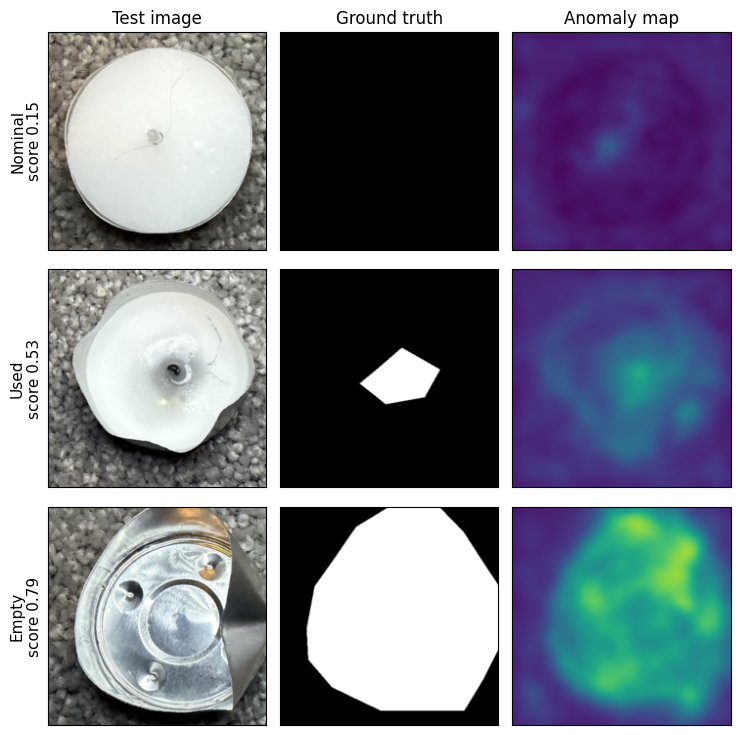

In [7]:
import torchvision.transforms as T
prep = T.Compose([T.Resize(256), T.CenterCrop(224)])
seg = np.load(glob.glob(f"{RUN}/segmentations_mvtec_tealight.npy")[0])

def mask_of(row):
    if row["type"] == "good":
        return np.zeros((224, 224))
    return np.array(prep(Image.open(f"{DATA}/tealight/ground_truth/{row['type']}/{row['name']}_mask.png")))

picks = [sc[sc.type == "good"].score.idxmax()]
for t in ["used", "empty"]:
    sub = sc[sc.type == t]
    picks.append((sub.score - sub.score.median()).abs().idxmin())

fig, axes = plt.subplots(3, 3, figsize=(7.5, 7.5))
for r, i in enumerate(picks):
    row = sc.loc[i]
    axes[r, 0].imshow(prep(Image.open(row["image"]).convert("RGB")))
    axes[r, 1].imshow(mask_of(row), cmap="gray", vmin=0, vmax=255)
    axes[r, 2].imshow(seg[i], cmap="viridis", vmin=0, vmax=1)
    axes[r, 0].set_ylabel(f"{'Nominal' if row['type']=='good' else row['type'].capitalize()}\nscore {row['score']:.2f}", fontsize=11)
for c, title in enumerate(["Test image", "Ground truth", "Anomaly map"]):
    axes[0, c].set_title(title, fontsize=12)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/tealight_heatmaps.png", dpi=150); plt.show()

highest nominal score: 0.155 | lowest defective score: 0.393
gap: 0.239


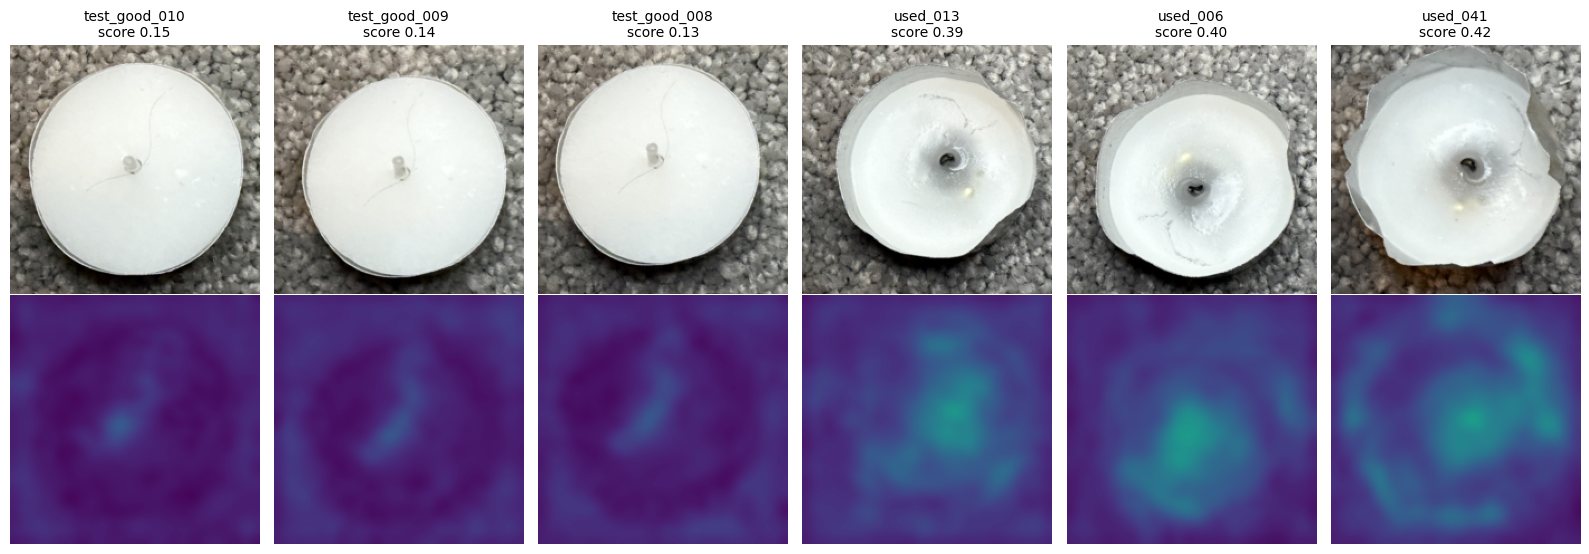

In [8]:
good = sc[sc.type == "good"].sort_values("score", ascending=False)
bad = sc[sc.type != "good"].sort_values("score")
print("highest nominal score:", round(good.score.max(), 3), "| lowest defective score:", round(bad.score.min(), 3))
print("gap:", round(bad.score.min() - good.score.max(), 3))

show = list(good.index[:3]) + list(bad.index[:3])
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for c, i in enumerate(show):
    row = sc.loc[i]
    axes[0, c].imshow(prep(Image.open(row["image"]).convert("RGB")))
    axes[1, c].imshow(seg[i], cmap="viridis", vmin=0, vmax=1)
    axes[0, c].set_title(f"{row['name']}\nscore {row['score']:.2f}", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/borderline_cases.png", dpi=120); plt.show()